In [5]:
# linear regresssion 

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
%matplotlib inline   
# so that i can display plots in this jupyter notebook

In [6]:
# I will be reading the dataset
df = pd.read_excel("C:\\Users\\lenovo\\Documents\\linear data.xlsx")

In [7]:
df.head()

,weight,height
0,45,120
1,58,135
2,48,123
3,60,145
4,70,160


In [8]:
# we are interesting to know how these two features are related . 


Text(0, 0.5, 'height')

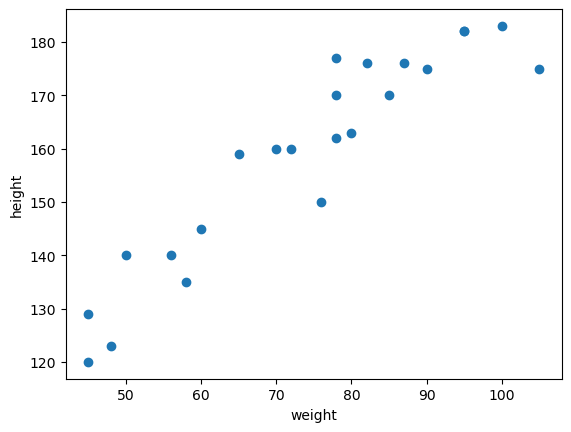

In [9]:
##scatter plot
plt.scatter(df["weight"],df["height"])
plt.xlabel("weight")
plt.ylabel("height")

In [10]:
# we can see linear realtionship 
#lets know relation is positive or not 
df.corr()

,weight,height
weight,1.000000,0.933729
height,0.933729,1.000000


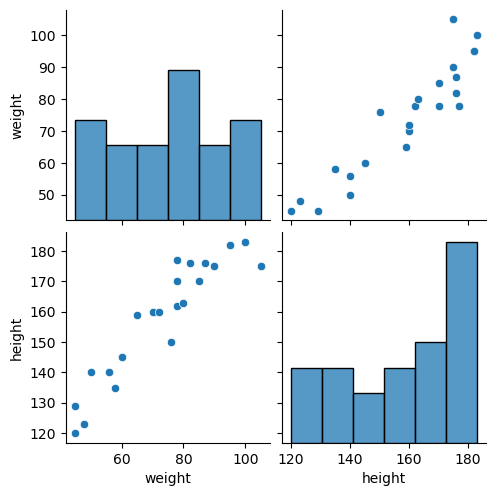

In [11]:
# pairplot() in seaborn show correlation  ,

import seaborn as sns 
sns.pairplot(df)

In [12]:
# multicolinearity : when we check  relation among more than 2 features 


In [13]:
# step 1 in lineary regression 
# independent and dependent features 
X = df["weight"]            # x created , is series 
X

0      45
1      58
2      48
3      60
4      70
5      78
6      80
7      90
8      95
9      78
10     82
11     95
12    105
13    100
14     85
15     78
16     50
17     65
18     76
19     87
20     45
21     56
22     72
Name: weight, dtype: int64

In [14]:
type(df)

pandas.core.frame.DataFrame

In [15]:
type(X)

pandas.core.series.Series

In [16]:
 X= df[["weight"]]   ## independent feature should be dataframe OR 2 dimension array ,not a series.

np.array(X).shape

(23, 1)

In [17]:
# but if write 
X_series = df["weight"]
np.array(X_series).shape        # it 1 dimension array : never keep this like that 


(23,)

In [18]:
# now create  dependent feature : we can take series in this case , because oiur target variable is always 1 d
y = df["height"]      # this can be in series or in 1-d ARRAY 

In [19]:
## train test split

from sklearn.model_selection  import train_test_split


In [20]:
X_train , X_test , y_train , y_test = train_test_split(X , y ,test_size =0.25,random_state = 42)


* if you dont put this random_state : every time you pick 75 % set and out into the traning set , and 25 % in testing dataset.,every time it pick up the different set .

In [21]:
X_train.shape    # should be in 2 -D array or dataframe 

(17, 1)

In [22]:
## standardization : we calculate Z- score = ((x - x bar) / standard deviation)
from sklearn.preprocessing import StandardScaler


In [23]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_train_scaled

array([[-0.87662801],
       [ 1.66773133],
       [ 0.33497168],
       [-1.48242785],
       [ 1.36483141],
       [-1.6641678 ],
       [-0.75546804],
       [-0.1496682 ],
       [ 0.21381171],
       [-1.36126788],
       [-0.99778797],
       [-0.02850823],
       [ 1.06193149],
       [ 0.57729161],
       [ 0.75903157],
       [ 0.88019153],
       [ 0.45613165]])

In [24]:
X_test_scaled = scaler.transform(X_test)

# why we do tranfrom ,not fit_transform in test set ?

when we do fit_transform(X_train) : it means it firstly calculate the mean and standard deviation of  X_train , and then find z- score .

when we do only transform(X_test) : it only calculate , the z =score of each value using the same means , and standard deviation of X_train .

reason why do it : 
* data leakage : we dont want our traning data to know any info about test data . 

In [25]:
X_test_scaled


array([[ 0.33497168],
       [ 0.33497168],
       [-1.6641678 ],
       [ 1.36483141],
       [-0.45256812],
       [ 1.97063125]])

In [26]:
## apply ml algorithms i.e. linear regression 

from sklearn.linear_model import LinearRegression

In [27]:
regression = LinearRegression()

In [28]:
regression.fit(X_train_scaled , y_train)

LinearRegression()

In [29]:
regression.coef_  # slope  

array([17.76418946])

In [30]:
regression.intercept_    # intercept 

157.0

In [31]:
regression.intercept_ # intercept is nothing but y = mx + c , this c .

157.0

* not : one unit movoment in th weitgh value , leads to the 17.76 movement in my height .

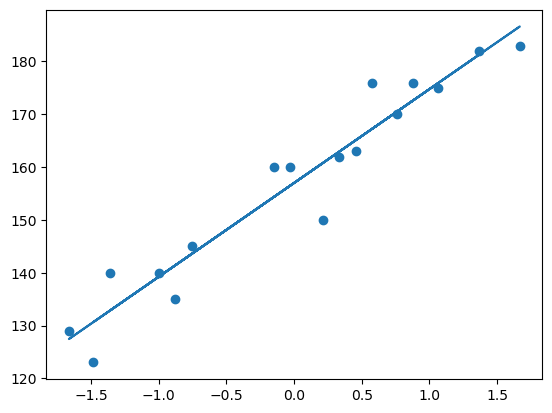

In [32]:
## plot traingn data , plot best fit line

plt.scatter(X_train_scaled ,y_train)
 # on top of this we plot . predicted values
plt.plot(X_train_scaled , regression.predict(X_train_scaled))


### predicted 
1. predicted height output = intercept + coef_ (weights)
2. y_pred_test = 65.4364 + 1.26(X_test)

In [33]:
y_pred_test = 157 + 17.76418946 *(X_test_scaled)
y_pred_test

array([[162.95050033],
       [162.95050033],
       [127.43740793],
       [181.24512369],
       [148.96049423],
       [192.00666684]])

In [34]:
y_pred = regression.predict(X_test_scaled)
y_pred

array([162.95050033, 162.95050033, 127.43740793, 181.24512369,
       148.96049423, 192.00666684])

In [35]:
# performance metrics 
from sklearn.metrics import mean_absolute_error , mean_squared_error 

In [36]:
mse = mean_squared_error(y_test , y_pred)
mae = mean_absolute_error(y_test ,y_pred)
rmse = np.sqrt(mse)
print(mse )
print(mae)
print(rmse)

115.4978590794849
9.389576031560585
10.746993025004013


## R^2 Squre 
formula 

##  R^2 = 1 - SSR/SST

R^2 =  coefficient of determination SSR = sum of squares of residuals SST = total sum of squares

In [37]:
from sklearn.metrics import r2_score


In [38]:
score = r2_score(y_test, y_pred)

In [39]:
score

0.7345724272670631

**Adjusted R2 = 1- [(1-R2)*(n-1)/(n-k-1)]**

where : 

R2 : the R2 of the model 

n: the number of observations 

k : the number of predictor  variables

In [40]:
#display adjusted R squared 
1-(1-score)*(len(y_test)-1)/(len(y_test)- X_test.shape[1]-1)

0.6682155340838288

# OLS linear regression

In [41]:
import statsmodels.api as sm


In [42]:
model = sm.OLS(y_train , X_train_scaled).fit()

In [43]:
prediction = model.predict(X_test)

In [44]:
prediction

15    1385.606778
9     1385.606778
0      799.388526
8     1687.597998
17    1154.672315
12    1865.239893
dtype: float64

In [45]:
print(prediction)

15    1385.606778
9     1385.606778
0      799.388526
8     1687.597998
17    1154.672315
12    1865.239893
dtype: float64


In [46]:
model.summary()

C:\Users\lenovo\anaconda3\Lib\site-packages\scipy\stats\_stats_py.py:1736: UserWarning: kurtosistest only valid for n>=20 ... continuing anyway, n=17
  warnings.warn("kurtosistest only valid for n>=20 ... continuing "


<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:                 height   R-squared (uncentered):                   0.013
Model:                            OLS   Adj. R-squared (uncentered):             -0.049
Method:                 Least Squares   F-statistic:                             0.2046
Date:                Tue, 10 Oct 2023   Prob (F-statistic):                       0.657
Time:                        15:39:35   Log-Likelihood:                         -110.09
No. Observations:                  17   AIC:                                      222.2
Df Residuals:                      16   BIC:                                      223.0
Df Model:                           1                                                  
Covariance Type:            nonrobust                                                  
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
x1            17.7642     39.270      0.452      0.657     -65.484     101.013
==============================================================================
Omnibus:                        0.591   Durbin-Watson:                   0.002
Prob(Omnibus):                  0.744   Jarque-Bera (JB):                0.391
Skew:                          -0.341   Prob(JB):                        0.822
Kurtosis:                       2.703   Cond. No.                         1.00
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

# note : 
coefficient we get from both methode , 
OLS and linear regresssion are same : 17.76

In [47]:
# prediction for new data 
regression.predict([[72]])

array([1436.02164094])

**result is not right , why ? because this '72' is not scaled to lets firstly scale it during passing in predict function**

In [48]:
regression.predict(scaler.transform([[72]]))

C:\Users\lenovo\anaconda3\Lib\site-packages\sklearn\base.py:465: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


array([156.49357444])

yeah ! not it is good

# POLYNOMIAL REGRESSION : more than two variable .

In [49]:
# dataset 
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
%matplotlib inline


In [50]:
# read dataset
df_index = pd.read_csv("C:\\Users\\lenovo\\Downloads\\economic_index.csv")

df_index

,Unnamed: 0,year,month,interest_rate,unemployment_rate,index_price
0,0,2017,12,2.75,5.3,1464
1,1,2017,11,2.50,5.3,1394
2,2,2017,10,2.50,5.3,1357
3,3,2017,9,2.50,5.3,1293
4,4,2017,8,2.50,5.4,1256
5,5,2017,7,2.50,5.6,1254
6,6,2017,6,2.50,5.5,1234
7,7,2017,5,2.25,5.5,1195
8,8,2017,4,2.25,5.5,1159
9,9,2017,3,2.25,5.6,1167


In [51]:
# drop unneccessary column
df_index.drop(columns = ["Unnamed: 0","year","month"] ,axis = 1, inplace = True)

In [52]:
df_index

,interest_rate,unemployment_rate,index_price
0,2.75,5.3,1464
1,2.50,5.3,1394
2,2.50,5.3,1357
3,2.50,5.3,1293
4,2.50,5.4,1256
5,2.50,5.6,1254
6,2.50,5.5,1234
7,2.25,5.5,1195
8,2.25,5.5,1159
9,2.25,5.6,1167


In [53]:
# check for null values in dataset 

df_index.isnull().sum()

interest_rate        0
unemployment_rate    0
index_price          0
dtype: int64

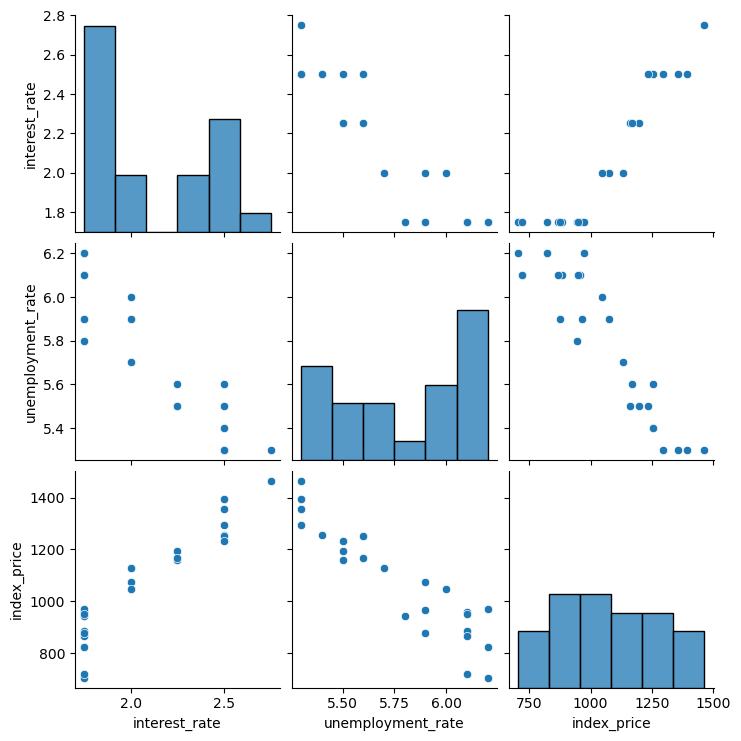

In [54]:
# visualizATION

import seaborn as sns
sns.pairplot(df_index)

In [55]:
df_index.corr()

,interest_rate,unemployment_rate,index_price
interest_rate,1.000000,-0.925814,0.935793
unemployment_rate,-0.925814,1.000000,-0.922338
index_price,0.935793,-0.922338,1.000000


Text(0, 0.5, 'unemployment rate')

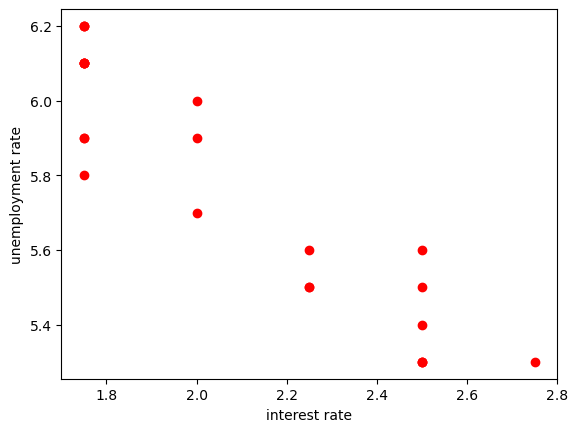

In [56]:
# visulaize the datapoints more closely

plt.scatter(df_index["interest_rate"],df_index["unemployment_rate"],color = "r")
plt.xlabel("interest rate")
plt.ylabel("unemployment rate")

In [57]:
#get my independent and dependent feature 
X = df_index.iloc[:,:-1]        # all feature except last one
y = df_index.iloc[:,-1]

In [58]:
X.head()

,interest_rate,unemployment_rate
0,2.75,5.3
1,2.50,5.3
2,2.50,5.3
3,2.50,5.3
4,2.50,5.4


In [59]:
y

0     1464
1     1394
2     1357
3     1293
4     1256
5     1254
6     1234
7     1195
8     1159
9     1167
10    1130
11    1075
12    1047
13     965
14     943
15     958
16     971
17     949
18     884
19     866
20     876
21     822
22     704
23     719
Name: index_price, dtype: int64

In [60]:
#train test split

from sklearn.model_selection import train_test_split
X_train ,X_test , y_train , y_test = train_test_split(X ,y , test_size = 0.25 ,random_state = 42)

<Axes: xlabel='interest_rate', ylabel='index_price'>

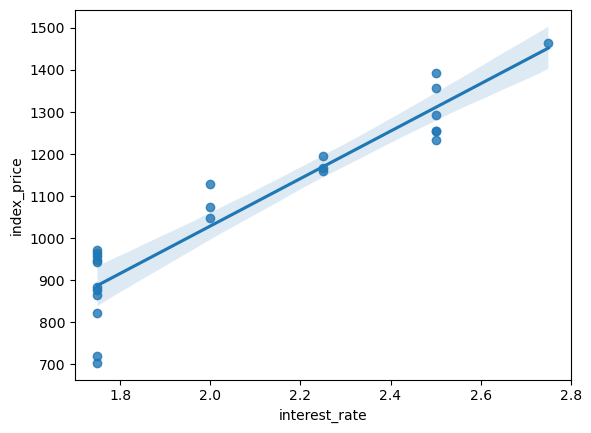

In [61]:
# 
import seaborn as sns
sns.regplot(data =  df_index , x = "interest_rate" , y = "index_price")

<Axes: xlabel='interest_rate', ylabel='unemployment_rate'>

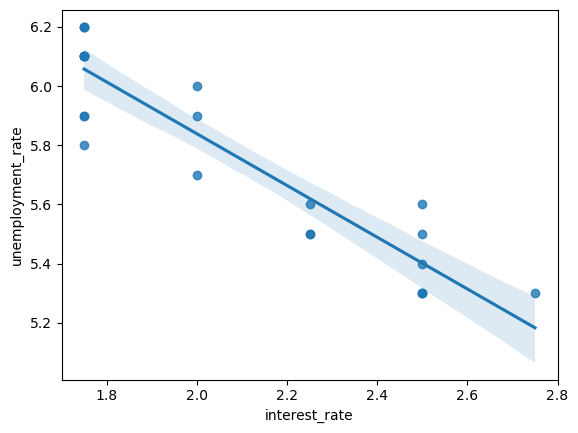

In [62]:
sns.regplot(data =  df_index , x = "interest_rate" , y = "unemployment_rate")

In [63]:
# shaded region tells : that we can do hyperparameter tune this line to that much extent

<Axes: xlabel='index_price', ylabel='unemployment_rate'>

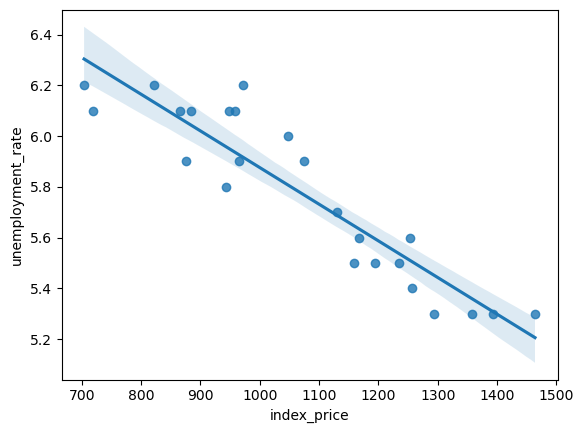

In [64]:
sns.regplot(data =  df_index , x = "index_price" , y = "unemployment_rate")

In [65]:
# scaling 

from sklearn.preprocessing import StandardScaler

In [66]:
scaler = StandardScaler()

In [67]:
X_train = scaler.fit_transform(X_train)
X_test =  scaler.fit_transform(X_test)

In [68]:
# linear regression 

from sklearn.linear_model import LinearRegression

regression = LinearRegression()

In [69]:
regression.fit(X_train , y_train)

LinearRegression()

In [105]:
regression.coef_

array([  88.27275507, -116.25716066])

In [106]:
regression.intercept_

1053.4444444444443

In [75]:
#cross validation

from sklearn.model_selection import cross_val_score

validation_score =  cross_val_score(regression, X_train , y_train , scoring = "neg_mean_squared_error", cv =3)

#cross-validation generator or an iterable,(cv)



In [76]:
validation_score

array([-4921.61331265, -7686.87497294, -5135.9962549 ])

In [77]:
# so it have 3 mean_square_error bcz , we have 2 cv

#lets find average of these scores

np.mean(validation_score)

-5914.828180162396

In [78]:
# prediction 

y_pred = regression.predict(X_test)

In [83]:
# performance matrics .

from sklearn.metrics import mean_absolute_error , mean_squared_error

mse = mean_squared_error(y_test, y_pred)

mae  = mean_absolute_error(y_test , y_pred)

rmse  = np.sqrt(mse)

print(mse)
print(mae)
print(rmse)

8108.567426306611
73.80444932337099
90.04758423359624


In [87]:
## R score
from sklearn.metrics import r2_score

score = r2_score(y_test , y_pred)

print(score)




0.7591371539010254


In [88]:
# display adjusted _ r sqaured
print(1 - (1 - score)* (len(y_test) -1)/(len(y_test) - X_test.shape[1]-1))


0.5985619231683756


# assumptions: after we do a prediction

# 1 plot scatter plot

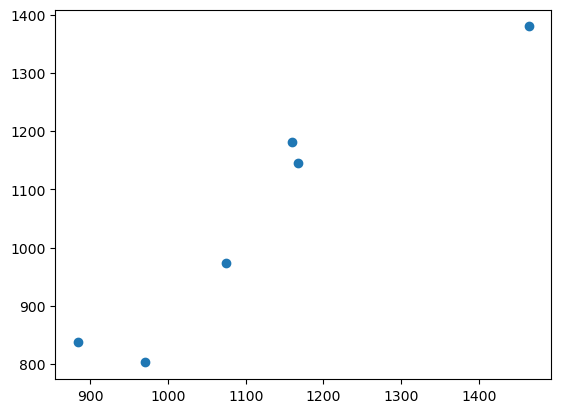

In [97]:
# 1. plot scatter plot :
    
plt.scatter(y_test,y_pred)

In [98]:
# there is linear relation ship bwtween y_test and y_pred , it indicate our model has predicted wel.


# 2 residuals

* displot should be normal

In [92]:
residuals = y_test - y_pred
print(residuals)

8     -21.746681
16    168.257203
0      84.165430
18     45.474004
11    101.146860
9      22.036518
Name: index_price, dtype: float64


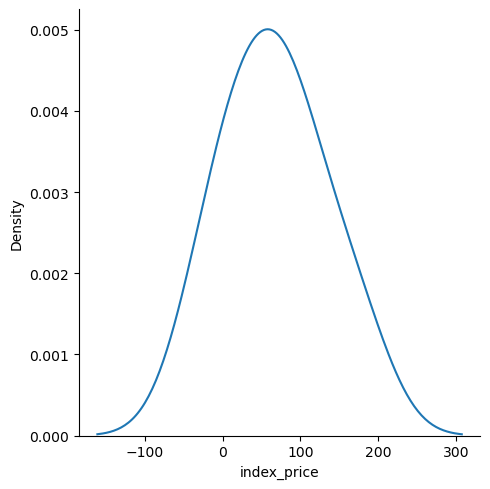

In [94]:
# is i plot these residuals :
# displot used in sns 
import seaborn as sns 

sns.displot(residuals , kind = "kde")

# kde : kernal density estimator



In [95]:
# normal curve we get  : it implies that model did good work


# 3 create a scatter plot with respectt to with  prediction and residuals

* should be uniformly distrinbuted


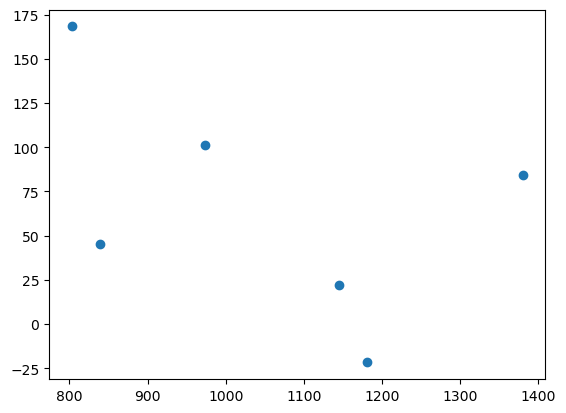

In [96]:

plt.scatter(y_pred , residuals)

# computer OLS (ordinary least square)

In [100]:
import statsmodels.api as sm

model = sm.OLS(y_train , X_train).fit()

In [104]:
model.summary()

C:\Users\lenovo\anaconda3\Lib\site-packages\scipy\stats\_stats_py.py:1736: UserWarning: kurtosistest only valid for n>=20 ... continuing anyway, n=18
  warnings.warn("kurtosistest only valid for n>=20 ... continuing "


<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:            index_price   R-squared (uncentered):                   0.035
Model:                            OLS   Adj. R-squared (uncentered):             -0.086
Method:                 Least Squares   F-statistic:                             0.2880
Date:                Tue, 10 Oct 2023   Prob (F-statistic):                       0.754
Time:                        16:13:13   Log-Likelihood:                         -150.85
No. Observations:                  18   AIC:                                      305.7
Df Residuals:                      16   BIC:                                      307.5
Df Model:                           2                                                  
Covariance Type:            nonrobust                                                  
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
x1            88.2728    658.295      0.134      0.895   -1307.250    1483.796
x2          -116.2572    658.295     -0.177      0.862   -1511.780    1279.266
==============================================================================
Omnibus:                        0.598   Durbin-Watson:                   0.007
Prob(Omnibus):                  0.741   Jarque-Bera (JB):                0.567
Skew:                          -0.361   Prob(JB):                        0.753
Kurtosis:                       2.517   Cond. No.                         4.78
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""